# Notebook 05 — Pipeline biết rủi ro (RQ1 + RQ2 + RQ3)

**Câu hỏi:** khi ghép chuỗi frame UAV thành bản đồ, làm sao biết *bước ghép nào đang sai*
mà không cần bản đồ chuẩn, và khi biết thì xử lý thế nào?

Notebook này trả lời ba câu hỏi nghiên cứu của đề tài (`RDR-0003`) trên cùng một hệ đo:

| RQ | Câu hỏi | Cách đo trong notebook |
|---|---|---|
| RQ1 | Chỉ báo rẻ nào báo được bước ghép sai? | So từng chỉ báo với sai số thật của bước đó (đo bằng matcher tham chiếu) |
| RQ2 | Khi nào nên gọi matcher mạnh? | Mô phỏng chính sách phân luồng, quét ngưỡng, so chi phí–chất lượng |
| RQ3 | Khi ghép vẫn rủi ro thì cứu thế nào? | Chạy 4 chiến lược (bỏ frame / rematch keyframe / tách submosaic / không cứu) dưới cùng ngưỡng |

**Thước đo "sai số thật" của một bước:** ghép chính cặp ảnh đó bằng matcher tham chiếu
(SIFT ảnh gốc, 4000 đặc trưng — đúng định nghĩa `RDR-0007`), rồi so hai homography trên
5 điểm mốc. Đây là bản mở rộng cấp-bước của metric `chain vs direct` đã chốt.

**Vì sao lại đo ở frame 80–125 / 0–45 mà không phải 20 frame đầu?** Vì 20 frame đầu của
cả hai sequence *không có lỗi nào* — đo ở đó thì không có ca nào để học. Chi tiết bằng chứng
ở `docs/logs/experiments/0001_failure_scan_windows.md`.

**Trạng thái:** đây là bản phân tích để nhóm chốt ngưỡng; ngưỡng trong notebook là **giá trị tạm**
(`TAU_*`), chưa được `RDR` phê chuẩn.


In [1]:
import hashlib
import json
import platform
import time
from datetime import datetime, timezone
from pathlib import Path

import cv2
import matplotlib
import numpy as np
import torch
from IPython.display import Markdown, display

# Chỉ ép backend không tương tác khi chạy như script; trong notebook phải hiển thị inline.
try:
    get_ipython  # noqa: B018
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
if not IN_NOTEBOOK:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

ROOT = Path.cwd() if (Path.cwd() / "requirements.txt").exists() else Path.cwd().parent
SEQUENCES = ("phantom3-village-kfs", "phantom3-grass-kfs")
# Cửa sổ chọn theo scan 160 bước (docs/logs/progress): nơi matcher thật sự sai
#   village: SIFT-640 sai 5-11 px ở các bước 86-98, 116-137 -> cửa sổ 80..125
#   grass:   EfficientLoFTR vỡ 5-190 px ngay từ bước đầu    -> cửa sổ 0..45
WINDOWS = {"phantom3-village-kfs": (80, 45), "phantom3-grass-kfs": (0, 45)}
MAX_SIDE = 640
MAX_KEYPOINTS = 2000
RANSAC_PX = 3.0
RATIO = 0.75
DEVICE = "cpu"
MIN_INLIERS = 100          # RDR-0007: ngưỡng hợp lệ của matcher tham chiếu
TOLERANCE_PX = 2.0         # ngưỡng "bước ghép sai": nằm ở mức nền nhiễu của chính SIFT (RDR-0007)
TAU_NCC = 0.95             # TẠM — nhóm chưa chốt bằng RDR
TAU_INLIER_RATIO = 0.30    # TẠM — nhóm chưa chốt bằng RDR
TAU_GRID = (0.90, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99)
ESCALATION_BUDGET = 0.25
ANCHOR_BACK = 3
CHEAP = "sift_bf"
STRONG = "superpoint_lightglue"
DIAGNOSTIC = "efficientloftr"
FULLRES = "superpoint_lightglue@full"
POLICIES = ("none", "drop", "anchor", "split")
print("Root:", ROOT, "| torch", torch.__version__, "| opencv", cv2.__version__)


Root: d:\fptu\_hoc-lieu\ky4\cvprj | torch 2.14.1+cpu | opencv 5.0.0


In [2]:
# Tải ảnh ở độ phân giải làm việc. Mọi homography trả về hệ pixel ảnh ĐÃ resize;
# hàm to_original() đưa về hệ pixel ảnh gốc để so với matcher tham chiếu.
def frames_of(sequence, start, count, max_side=MAX_SIDE):
    folders = list((ROOT / "data" / sequence).rglob("rgb"))
    if len(folders) != 1:
        raise ValueError(f"cần đúng một thư mục rgb: {sequence}")
    files = sorted(folders[0].glob("*.jpg"), key=lambda p: float(p.stem))[start:start + count + 1]
    if len(files) != count + 1:
        raise ValueError(f"{sequence}: chỉ có {len(files)} frame, cần {count + 1}")
    images, size = [], None
    for path in files:
        bgr = cv2.imread(str(path))
        if bgr is None:
            raise ValueError(f"không đọc được {path}")
        size = (bgr.shape[1], bgr.shape[0])
        scale = min(1, max_side / max(bgr.shape[:2]))
        resized = (max(32, int(bgr.shape[1] * scale) // 32 * 32),
                   max(32, int(bgr.shape[0] * scale) // 32 * 32))
        images.append(cv2.cvtColor(cv2.resize(bgr, resized, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB))
    return files, images, size


def to_original(H, processed, original):
    """H ở hệ pixel ảnh resize -> hệ pixel ảnh gốc."""
    D = np.diag([original[0] / processed[0], original[1] / processed[1], 1.0])
    return D @ H @ np.linalg.inv(D)


class LazyImages:
    """Danh sách ảnh gốc chỉ nạp khi thật sự dùng — leo thang full-res chỉ cần vài frame."""

    def __init__(self, files):
        self.files, self.cache = list(files), {}

    def __getitem__(self, index):
        if index not in self.cache:
            bgr = cv2.imread(str(self.files[index]))
            if bgr is None:
                raise ValueError(f"không đọc được {self.files[index]}")
            self.cache[index] = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        return self.cache[index]

    def __len__(self):
        return len(self.files)


def dump(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")


def fmt(value, width, digits=2):
    """In số an toàn: giá trị có thể là None (chưa đo được) thì ghi 'n/a'."""
    return "n/a".rjust(width) if value is None else f"{value:{width}.{digits}f}"


In [3]:
# Adapter matcher — giữ nguyên giao diện của notebook 03 để dùng chung.
def tensor(image, device):
    return torch.from_numpy(image.copy()).permute(2, 0, 1).float().to(device) / 255


def load_matcher(method, device, max_points=MAX_KEYPOINTS):
    if method == CHEAP:
        detector = cv2.SIFT_create(nfeatures=max_points)
        matcher = cv2.BFMatcher(cv2.NORM_L2)

        def match(a, b):
            detected = [detector.detectAndCompute(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), None) for img in (a, b)]
            (k0, d0), (k1, d1) = detected
            if d0 is None or d1 is None or len(d1) < 2:
                return np.empty((0, 2), np.float32), np.empty((0, 2), np.float32)
            good = [m for pair in matcher.knnMatch(d0, d1, k=2) if len(pair) == 2
                    for m, n in [pair] if m.distance < RATIO * n.distance]
            return (np.float32([k0[m.queryIdx].pt for m in good]).reshape(-1, 2),
                    np.float32([k1[m.trainIdx].pt for m in good]).reshape(-1, 2))
        return match
    if method == STRONG:
        from lightglue import LightGlue, SuperPoint
        from lightglue.utils import rbd
        extractor = SuperPoint(max_num_keypoints=max_points).eval().to(device)
        matcher = LightGlue(features="superpoint").eval().to(device)
        extractor.requires_grad_(False)
        matcher.requires_grad_(False)

        @torch.inference_mode()
        def match(a, b):
            features = [extractor.extract(tensor(img, device), resize=None) for img in (a, b)]
            if min(f["keypoints"].shape[1] for f in features) == 0:
                return np.empty((0, 2), np.float32), np.empty((0, 2), np.float32)
            index = rbd(matcher({"image0": features[0], "image1": features[1]}))["matches"]
            return (rbd(features[0])["keypoints"][index[:, 0]].cpu().numpy(),
                    rbd(features[1])["keypoints"][index[:, 1]].cpu().numpy())
        return match
    if method == DIAGNOSTIC:
        from transformers import AutoImageProcessor, AutoModelForKeypointMatching
        source = "zju-community/efficientloftr"
        revision = "face1a79050ffa3e9da28720d1cf93aaf2e8f421"
        processor = AutoImageProcessor.from_pretrained(source, revision=revision)
        model = AutoModelForKeypointMatching.from_pretrained(source, revision=revision).eval().to(device)
        model.requires_grad_(False)

        @torch.inference_mode()
        def match(a, b):
            inputs = processor([a, b], do_resize=False, return_tensors="pt").to(device)
            out = processor.post_process_keypoint_matching(
                model(**inputs), [[a.shape[:2], b.shape[:2]]], threshold=0.2)[0]
            return out["keypoints0"].cpu().numpy(), out["keypoints1"].cpu().numpy()
        return match
    raise ValueError(method)


In [4]:
# Matcher tham chiếu (RDR-0007) + hình học + chỉ báo rẻ.
REFERENCE_SIFT = cv2.SIFT_create(nfeatures=4000)
REFERENCE_BF = cv2.BFMatcher(cv2.NORM_L2)
_REFERENCE_CACHE = {}
_MATCH_CACHE = {}


def reference_pair(path_a, path_b):
    """H của cặp (b -> a) ở ẢNH GỐC bằng SIFT 4000 đặc trưng; có cache."""
    key = (str(path_a), str(path_b))
    if key in _REFERENCE_CACHE:
        return _REFERENCE_CACHE[key]
    started = time.perf_counter()
    grays = [cv2.imread(str(p), cv2.IMREAD_GRAYSCALE) for p in (path_a, path_b)]
    if any(g is None for g in grays):
        raise ValueError("reference: không đọc được ảnh")
    detected = [REFERENCE_SIFT.detectAndCompute(g, None) for g in grays]
    (k0, d0), (k1, d1) = detected
    if d0 is None or d1 is None:
        raise ValueError("reference: không đủ đặc trưng")
    good = [m for pair in REFERENCE_BF.knnMatch(d0, d1, k=2) if len(pair) == 2
            for m, n in [pair] if m.distance < RATIO * n.distance]
    if len(good) < 4:
        raise ValueError(f"reference: chỉ {len(good)} match")
    p0 = np.float32([k0[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    p1 = np.float32([k1[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    cv2.setRNGSeed(0)
    H, mask = cv2.findHomography(p1, p0, cv2.RANSAC, RANSAC_PX)
    if H is None or not np.isfinite(H).all():
        raise ValueError("reference: RANSAC thất bại")
    _REFERENCE_CACHE[key] = (H / H[2, 2], int(mask.sum()), len(good), time.perf_counter() - started)
    return _REFERENCE_CACHE[key]


def geometry(p0, p1):
    """H ánh xạ p1 -> p0 (frame hiện tại -> frame trước), RANSAC cố định seed."""
    if len(p0) < 4:
        return None, np.zeros(len(p0), bool), None
    cv2.setRNGSeed(0)
    H, mask = cv2.findHomography(p1, p0, cv2.RANSAC, RANSAC_PX)
    if H is None or mask is None or not np.isfinite(H).all() or np.linalg.matrix_rank(H) != 3:
        return None, np.zeros(len(p0), bool), None
    good = mask.ravel().astype(bool)
    if good.sum() < 4:
        return None, good, None
    predicted = cv2.perspectiveTransform(p1[good].reshape(-1, 1, 2), H).reshape(-1, 2)
    rmse = float(np.sqrt(np.mean(np.sum((predicted - p0[good]) ** 2, axis=1))))
    return H, good, rmse if np.isfinite(rmse) else None


def quad_points(shape):
    h, w = shape[:2]
    return np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)


def indicators(a, b, p0, p1, good, H):
    """Sáu chỉ báo rẻ: đếm/tỉ lệ điểm, phân tán không gian, vùng chồng, tương phản sau khi ghép, RMSE."""
    h, w = b.shape[:2]
    inliers = p0[good]
    out = {"matches": int(len(p0)), "inliers": int(good.sum()),
           "inlier_ratio": float(good.sum() / max(len(p0), 1))}
    hull = cv2.convexHull(np.float32(inliers)).reshape(-1, 2) if inliers.shape[0] >= 3 else None
    out["hull_area_ratio"] = float(cv2.contourArea(hull) / (h * w)) if hull is not None else 0.0
    inter, _ = cv2.intersectConvexConvex(quad_points(a.shape), cv2.perspectiveTransform(quad_points(b.shape), H))
    out["overlap_ratio"] = float(inter / float(w * h))
    gray_a = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY).astype(np.float32)
    gray_b = cv2.cvtColor(b, cv2.COLOR_RGB2GRAY).astype(np.float32)
    inverse = np.linalg.inv(H)
    warped = cv2.warpPerspective(gray_a, inverse, (w, h))
    mask = cv2.warpPerspective(np.ones_like(gray_a), inverse, (w, h)) > 0.5
    x, y = warped[mask], gray_b[mask]
    x, y = x - x.mean(), y - y.mean()
    out["photo_ncc"] = float((x * y).sum() / (np.sqrt((x * x).sum() * (y * y).sum()) + 1e-9))
    out["photo_bad_frac"] = float(np.mean(np.abs(x - y) > 25))
    return out


def marker_error(H_a, H_b, size):
    pts = np.float32([[0, 0], [size[0], 0], [size[0], size[1]], [0, size[1]],
                      [size[0] / 2, size[1] / 2]]).reshape(-1, 1, 2)
    a = cv2.perspectiveTransform(pts, H_a).reshape(-1, 2)
    b = cv2.perspectiveTransform(pts, H_b).reshape(-1, 2)
    if not (np.isfinite(a).all() and np.isfinite(b).all()):
        raise ValueError("phép chiếu không hữu hạn")
    return float(np.mean(np.linalg.norm(a - b, axis=1)))


def estimate_cached(method, matcher, images, files, index_a, index_b, size_processed, size_original,
                    paths=None):
    """Đo một cặp bằng matcher; cache toàn cục để các chiến lược RQ3 dùng lại kết quả."""
    key = (method, size_processed, str((paths or files)[index_a]), str((paths or files)[index_b]))
    if key in _MATCH_CACHE:
        return _MATCH_CACHE[key]
    started = time.perf_counter()
    p0, p1 = matcher(images[index_a], images[index_b])
    seconds = time.perf_counter() - started
    p0 = np.asarray(p0, np.float32).reshape(-1, 2)
    p1 = np.asarray(p1, np.float32).reshape(-1, 2)
    H, good, rmse = geometry(p0, p1)
    row = {"status": "success" if H is not None else "failed", "seconds": seconds, "rmse_px": rmse}
    if H is not None:
        row.update(indicators(images[index_a], images[index_b], p0, p1, good, H))
        row["H_processed"] = H.tolist()
        row["H_original"] = to_original(H, size_processed, size_original).tolist()
    _MATCH_CACHE[key] = row
    return row


def risk(row, tau_ncc=TAU_NCC, tau_ratio=TAU_INLIER_RATIO):
    """Rủi ro: matcher không ra H, tương phản sau khi ghép kém, hoặc quá ít inlier."""
    if row["status"] != "success":
        return True
    return row["photo_ncc"] < tau_ncc or row["inlier_ratio"] < tau_ratio


In [5]:
# Đo cả cửa sổ: matcher tham chiếu cho từng bước + ba matcher, lưu mọi chỉ báo.
def scan_window(sequence, start, steps):
    files, images, size_original = frames_of(sequence, start, steps)
    size_processed = (images[0].shape[1], images[0].shape[0])
    reference, chain = {}, [np.eye(3)]
    for step in range(1, steps + 1):
        H_ref, inliers, matches, seconds = reference_pair(files[step - 1], files[step])
        reference[step] = {"H_original": H_ref.tolist(), "inliers": inliers, "matches": matches,
                           "seconds": seconds}
        chain.append(chain[-1] @ H_ref)
    matchers, rows = {}, {}
    for method in (CHEAP, STRONG, DIAGNOSTIC):
        matchers[method] = load_matcher(method, DEVICE)
        per_step = {}
        for step in range(1, steps + 1):
            row = dict(estimate_cached(method, matchers[method], images, files, step - 1, step,
                                       size_processed, size_original), step=step, tier=method)
            if row["status"] == "success":
                H = to_original(np.array(row["H_processed"]), size_processed, size_original)
                row["step_error_px"] = marker_error(H, np.array(reference[step]["H_original"]), size_original)
            per_step[step] = row
        rows[method] = per_step
        errors = [r["step_error_px"] for r in per_step.values() if r["status"] == "success"]
        print(f"  {method:22} step_err trung vị {np.median(errors):6.2f} | lớn nhất {np.max(errors):8.2f} px | "
              f"{sum(r['seconds'] for r in per_step.values()):6.1f}s | "
              f"lỗi hẳn {sum(1 for r in per_step.values() if r['status'] != 'success')} bước")
    return {"sequence": sequence, "start": start, "steps": steps, "size_original": size_original,
            "size_processed": size_processed, "files": files, "images": images,
            "reference": reference, "reference_chain": [c.tolist() for c in chain],
            "rows": rows}


In [6]:
# RQ1: chỉ báo nào báo được bước ghép sai? (Spearman + AUC so với sai số thật của bước)
INDICATOR_NAMES = ("photo_ncc", "photo_bad_frac", "inlier_ratio", "inliers", "matches",
                   "hull_area_ratio", "overlap_ratio", "rmse_px")


def average_ranks(values):
    """Rank trung bình cho giá trị đồng hạng (đúng chuẩn Spearman; tránh rank giả theo thứ tự xuất hiện)."""
    values = np.asarray(values, float)
    ranks = np.empty(len(values), float)
    ranks[np.argsort(values, kind="mergesort")] = np.arange(1, len(values) + 1)
    unique, inverse, counts = np.unique(values, return_inverse=True, return_counts=True)
    if len(unique) == len(values):
        return ranks
    inverse = inverse.reshape(-1)
    for index, count in enumerate(counts):
        if count > 1:
            ranks[inverse == index] = ranks[inverse == index].mean()
    return ranks


def spearman(x, y):
    """Spearman có xử lý đồng hạng; trả None nếu một biến không đổi (tương quan vô định)."""
    rx = average_ranks(x) - (len(x) + 1) / 2
    ry = average_ranks(y) - (len(y) + 1) / 2
    denominator = np.sqrt((rx * rx).sum() * (ry * ry).sum())
    return float((rx * ry).sum() / denominator) if denominator > 0 else None


def auc(scores, labels):
    """AUC kiểu hạng, không cần sklearn; score lớn hơn = nghi ngờ hơn."""
    scores, labels = np.asarray(scores, float), np.asarray(labels, bool)
    if labels.all() or not labels.any():
        return None      # không có cả hai lớp -> AUC vô nghĩa, ghi None chứ không ghi NaN
    ranks = np.empty(len(scores), float)
    ranks[np.argsort(scores)] = np.arange(1, len(scores) + 1)
    for value, count in zip(*np.unique(scores, return_counts=True)):
        if count > 1:
            ranks[scores == value] = ranks[scores == value].mean()
    n_pos, n_neg = labels.sum(), (~labels).sum()
    return float((ranks[labels].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def rq1_table(scans, tolerance_px=TOLERANCE_PX):
    table = []
    for scan in scans:
        for tier, per_step in scan["rows"].items():
            rows = [r for r in per_step.values() if r["status"] == "success"]
            labels = [r["step_error_px"] > tolerance_px for r in rows]
            for name in INDICATOR_NAMES:
                if name not in rows[0]:
                    continue
                values = [r[name] for r in rows]
                # AUC quy về "kỹ năng phát hiện": chiều nào tách tốt hơn thì lấy, nên luôn >= 0.5.
                # Chiều thật của từng chỉ báo đọc ở cột ρ (dấu ngược nhau tuỳ chỉ báo).
                raw = auc([-v for v in values], labels)
                table.append({"sequence": scan["sequence"], "tier": tier, "indicator": name,
                              "n_steps": len(rows), "n_bad_steps": int(sum(labels)),
                              "spearman_vs_step_error": spearman(values, [r["step_error_px"] for r in rows]),
                              "auc_bad_step": None if raw is None else max(raw, 1 - raw)})
    return table


In [7]:
# RQ2: mô phỏng chính sách phân luồng trên log đã đo (không chạy lại matcher).
def chain_from_steps(chosen, reference_chain):
    chain = [np.eye(3)]
    for position in range(1, len(reference_chain)):
        pick = chosen.get(position)
        if pick is None:
            break
        chain.append(chain[-1] @ np.array(pick["H_original"], float))
    return chain


def simulate(scan, policy, strong=STRONG, tau_ncc=TAU_NCC, tau_ratio=TAU_INLIER_RATIO, strong_rows=None):
    rows = scan["rows"]
    strong_rows = strong_rows or rows[strong]
    size_original = scan["size_original"]
    reference_chain = [np.array(c, float) for c in scan["reference_chain"]]
    chosen, seconds, escalations = {}, 0.0, 0
    for step in range(1, scan["steps"] + 1):
        cheap = rows[CHEAP][step]
        if policy == "classical":
            pick, run = cheap, [cheap]
        elif policy == "learned":
            pick, run = strong_rows[step], [strong_rows[step]]
        else:
            if risk(cheap, tau_ncc, tau_ratio):
                pick, run = strong_rows[step], [cheap, strong_rows[step]]
                escalations += 1
            else:
                pick, run = cheap, [cheap]
        seconds += sum(r["seconds"] for r in run)
        chosen[step] = pick
    chain = chain_from_steps(chosen, reference_chain)
    drift = [marker_error(chain[i], reference_chain[i], size_original) for i in range(len(chain))]
    errors = [chosen[s]["step_error_px"] for s in sorted(chosen) if chosen[s]["status"] == "success"]
    return {"policy": policy, "tau_ncc": tau_ncc if policy == "routed" else None,
            "steps": len(chosen), "failed_steps": sum(1 for s in chosen if chosen[s]["status"] != "success"),
            "escalations": escalations, "escalation_rate": escalations / max(len(chosen), 1),
            "seconds": seconds, "step_error_mean_px": float(np.mean(errors)),
            "step_error_p95_px": float(np.percentile(errors, 95)), "step_error_max_px": float(np.max(errors)),
            "final_drift_px": drift[-1], "drift_series": drift}


def choose_tau(sweep, budget=ESCALATION_BUDGET):
    """Ngưỡng LỚN NHẤT mà mọi sequence vẫn nằm trong ngân sách leo thang.

    Leo thang đơn điệu theo τ (τ càng cao càng nhiều bước bị gắn cờ), nên điểm làm việc hợp lý là
    ngưỡng cao nhất còn trong ngân sách — tức là dùng hết ngân sách để bắt lỗi, chứ không phải ít nhất.
    """
    routed = [row for row in sweep if row["policy"] == "routed" and row["tau_ncc"] is not None]
    if not routed:
        return None
    eligible = [tau for tau in {row["tau_ncc"] for row in routed}
                if all(row["escalation_rate"] <= budget for row in routed if row["tau_ncc"] == tau)]
    return max(eligible) if eligible else None


In [8]:
# RQ3: pipeline online — ngưỡng rủi ro + chiến lược phục hồi, chạy thật (không mô phỏng).
class OnlinePipeline:
    def __init__(self, method, matcher, files, images, size_original, policy,
                 tau_ncc=TAU_NCC, tau_ratio=TAU_INLIER_RATIO, anchor_back=ANCHOR_BACK):
        self.method = method
        self.matcher = matcher
        self.files = files
        self.images = images
        self.size_original = size_original
        self.size_processed = (images[0].shape[1], images[0].shape[0])
        self.policy = policy
        self.tau_ncc = tau_ncc
        self.tau_ratio = tau_ratio
        self.anchor_back = anchor_back
        self.cost = 0.0
        self.triggers = self.skips = self.anchored = self.splits = 0
        self.submosaic_of = {0: 0}
        self.submosaic_root = {0: 0}      # id submosaic -> CHỈ SỐ frame gốc của nó
        self.H_to_root = {0: np.eye(3)}
        self.steps = {}

    def estimate(self, index_a, index_b):
        row = estimate_cached(self.method, self.matcher, self.images, self.files, index_a, index_b,
                              self.size_processed, self.size_original)
        self.cost += row["seconds"]          # tính chi phí kể cả khi lấy từ cache
        return row

    def step_error(self, previous, current, H_original):
        H_ref = np.array(reference_pair(self.files[previous], self.files[current])[0], float)
        return marker_error(np.array(H_original, float), H_ref, self.size_original)

    def try_anchor(self, placed, index):
        for anchor in range(placed[-1] - 1, max(-1, placed[-1] - 1 - self.anchor_back), -1):
            candidate = self.estimate(anchor, index)
            if not risk(candidate, self.tau_ncc, self.tau_ratio):
                return dict(candidate, anchor=anchor)
        return None

    def run(self, steps):
        self.steps_total = steps
        placed, submosaic, index = [0], 0, 1
        while index <= steps:
            previous = placed[-1]
            row = self.estimate(previous, index)
            reason, used = "tier", row
            if risk(row, self.tau_ncc, self.tau_ratio):
                self.triggers += 1
                if self.policy == "none":
                    reason = "accept_risky"
                elif self.policy == "drop":
                    used, reason = None, "drop"
                elif self.policy == "split":
                    used, reason = None, "split"
                elif self.policy == "anchor":
                    used = self.try_anchor(placed, index)
                    reason = "anchor" if used else "drop"
            if used is not None and used["status"] == "success":
                root = used["anchor"] if reason == "anchor" else previous
                self.H_to_root[index] = self.H_to_root[root] @ np.array(used["H_original"], float)
                self.submosaic_of[index] = self.submosaic_of[root]
                self.steps[index] = {"reason": reason, "anchor": root,
                                     "step_error_px": self.step_error(root, index, used["H_original"])}
                placed.append(index)
                if reason == "anchor":
                    self.anchored += 1
            elif reason == "split":
                submosaic += 1
                self.splits += 1
                self.H_to_root[index] = np.eye(3)
                self.submosaic_of[index] = submosaic
                self.submosaic_root[submosaic] = index
                placed.append(index)
            else:
                self.skips += 1
            index += 1
        self.placed_total = len(placed)
        return self

    def summary(self):
        placed = sorted(self.steps)          # chỉ các frame có bước ghép được ghi nhận
        errors = [self.steps[i]["step_error_px"] for i in placed]
        drift = {}
        for index in placed:
            root = self.submosaic_root[self.submosaic_of[index]]      # frame gốc, không phải id submosaic
            reference_chain = np.eye(3)
            for step in range(root + 1, index + 1):
                reference_chain = reference_chain @ np.array(reference_pair(self.files[step - 1], self.files[step])[0], float)
            drift[index] = marker_error(self.H_to_root[index], reference_chain, self.size_original)
        return {"policy": self.policy, "matcher": self.method,
                "frames_placed": self.placed_total,          # tính cả frame gốc mảnh và frame 0
                "frames_requested": self.steps_total + 1,
                "frames_with_step": len(placed),
                "submosaics": self.splits + 1, "triggers": self.triggers, "skipped": self.skips,
                "anchored": self.anchored, "seconds": self.cost,
                "step_error_mean_px": float(np.mean(errors)) if errors else None,
                "step_error_p95_px": float(np.percentile(errors, 95)) if errors else None,
                "step_error_max_px": float(np.max(errors)) if errors else None,
                "drift_series": [drift[i] for i in sorted(drift)],
                "drift_max_px": float(np.max(list(drift.values()))) if drift else None,
                "drift_final_px": drift[max(drift)] if drift else None}


def run_policies(scan, method, tau_ncc, policies=POLICIES):
    matcher = load_matcher(method, DEVICE)
    out = []
    for policy in policies:
        pipeline = OnlinePipeline(method, matcher, scan["files"], scan["images"],
                                  scan["size_original"], policy, tau_ncc=tau_ncc).run(scan["steps"])
        summary = pipeline.summary()
        out.append({"sequence": scan["sequence"], **summary})
        print(f"  {method:20} {policy:7} đặt {summary['frames_placed']:3}/{scan['steps'] + 1} frame | "
              f"trigger {summary['triggers']:2} | submosaic {summary['submosaics']} | "
              f"step_err max {fmt(summary['step_error_max_px'], 8)} | drift max {fmt(summary['drift_max_px'], 9)} px")
    return out


In [9]:
# Chạy toàn bộ: RQ1 trên 2 sequence, RQ2 quét ngưỡng + leo thang ảnh gốc, RQ3 bốn chiến lược.
torch.set_num_threads(4)
cv2.setNumThreads(4)
torch.manual_seed(0)
STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
# Đường dẫn cố định (như notebook 04) để RDR/tài liệu trích dẫn được; mọi lần chạy ghi đè,
# dấu vết từng lần nằm ở manifest.stamp + hash đầu vào.
TARGET = ROOT / "notebooks" / "outputs" / "05_failure_aware"
TARGET.mkdir(parents=True, exist_ok=True)
REPORT = {"stamp": STAMP, "scope": "RQ1/RQ2/RQ3 — đo trên cửa sổ chọn theo scan 160 bước",
          "manifest": {"platform": platform.platform(), "torch": torch.__version__,
                       "opencv": cv2.__version__, "numpy": np.__version__, "device": DEVICE,
                       "max_side": MAX_SIDE, "max_keypoints": MAX_KEYPOINTS, "ransac_px": RANSAC_PX,
                       "seed": 0, "windows": {s: list(WINDOWS[s]) for s in SEQUENCES},
                       "cheap": CHEAP, "strong": STRONG, "diagnostic": DIAGNOSTIC,
                       "tau_ncc_default": TAU_NCC, "tau_inlier_ratio_default": TAU_INLIER_RATIO,
                       "tolerance_px": TOLERANCE_PX,
                       "note": "TAU_* là giá trị tạm để chạy; ngưỡng chính thức phải do nhóm chốt bằng RDR"},
          "scans": [], "rq1": [], "rq2": [], "rq3": [], "inputs": []}

SCANS = []
for sequence in SEQUENCES:
    start, steps = WINDOWS[sequence]
    print(f"\n=== {sequence}: frame {start}..{start + steps}")
    scan = scan_window(sequence, start, steps)
    SCANS.append(scan)
    REPORT["inputs"].extend({"path": str(p.relative_to(ROOT)), "sha256": hashlib.sha256(p.read_bytes()).hexdigest()}
                            for p in scan["files"])
    REPORT["scans"].append({"sequence": sequence, "start": start, "steps": steps,
                            "reference_inliers_min": min(v["inliers"] for v in scan["reference"].values()),
                            "rows": {t: {str(k): v for k, v in scan["rows"][t].items()} for t in scan["rows"]}})
    dump(TARGET / f"scan_{sequence}.json", {"sequence": sequence, "start": start, "steps": steps,
                                            "reference": {str(k): v for k, v in scan["reference"].items()},
                                            "rows": {t: {str(k): v for k, v in scan["rows"][t].items()}
                                                     for t in scan["rows"]}})
REPORT["rq1"] = rq1_table(SCANS)
print(f"\nRQ1: {len(REPORT['rq1'])} dòng chỉ báo đã tính")



=== phantom3-village-kfs: frame 80..125
  sift_bf                step_err trung vị   1.87 | lớn nhất     9.58 px |    3.4s | lỗi hẳn 0 bước


d:\fptu\_hoc-lieu\ky4\cvprj\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


  superpoint_lightglue   step_err trung vị   2.42 | lớn nhất     8.60 px |   55.8s | lỗi hẳn 0 bước


d:\fptu\_hoc-lieu\ky4\cvprj\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


  efficientloftr         step_err trung vị  15.37 | lớn nhất  1113.83 px |   86.6s | lỗi hẳn 0 bước

=== phantom3-grass-kfs: frame 0..45
  sift_bf                step_err trung vị   0.47 | lớn nhất     0.99 px |    2.4s | lỗi hẳn 0 bước
  superpoint_lightglue   step_err trung vị   1.19 | lớn nhất     4.01 px |   43.8s | lỗi hẳn 0 bước
  efficientloftr         step_err trung vị   9.34 | lớn nhất   313.13 px |   85.6s | lỗi hẳn 0 bước

RQ1: 48 dòng chỉ báo đã tính


In [10]:
# RQ2 — quét ngưỡng, chọn điểm làm việc, rồi thử leo thang lên ẢNH GỐC ở đúng các bước bị gắn cờ.
for scan in SCANS:
    sweep = [simulate(scan, "classical"), simulate(scan, "learned")]
    sweep += [simulate(scan, "routed", tau_ncc=tau) for tau in TAU_GRID]
    tau = choose_tau(sweep)
    fullres_rows = None
    if tau is not None and FULLRES not in scan["rows"]:
        matcher = load_matcher(STRONG, DEVICE)
        flagged = [s for s in range(1, scan["steps"] + 1)
                   if risk(scan["rows"][CHEAP][s], tau, TAU_INLIER_RATIO)]
        full_images = LazyImages(scan["files"])
        full = {}
        for step in flagged:
            row = estimate_cached(FULLRES, matcher, full_images, scan["files"], step - 1, step,
                                  scan["size_original"], scan["size_original"], paths=scan["files"])
            row = dict(row, step=step, tier=FULLRES)
            if row["status"] == "success":
                row["step_error_px"] = marker_error(np.array(row["H_original"], float),
                                                    np.array(scan["reference"][step]["H_original"], float),
                                                    scan["size_original"])
            full[step] = row
        fullres_rows = {step: (full[step] if step in full else dict(scan["rows"][STRONG][step], tier=FULLRES))
                        for step in range(1, scan["steps"] + 1)}
        del matcher
        REPORT["rq2_fullres_detail"] = REPORT.get("rq2_fullres_detail", [])
        REPORT["rq2_fullres_detail"].append({"sequence": scan["sequence"], "tau": tau,
                                             "flagged_steps": flagged,
                                             "fullres_step_error_mean_px": float(np.mean(
                                                 [full[s]["step_error_px"] for s in flagged]))
                                             if flagged else None,
                                             "native_px_step_error_mean_px": float(np.mean(
                                                 [scan["rows"][STRONG][s]["step_error_px"] for s in flagged]))
                                             if flagged else None})
    for row in sweep:
        REPORT["rq2"].append({"sequence": scan["sequence"], **row})
    REPORT.setdefault("tau_chosen", {})[scan["sequence"]] = tau
    if fullres_rows is not None:
        routed_full = simulate(scan, "routed", tau_ncc=tau, strong_rows=fullres_rows)
        REPORT["rq2"].append({"sequence": scan["sequence"], **routed_full, "policy": "routed_fullres"})
    print(f"\nRQ2 {scan['sequence']}: chọn τ_ncc = {tau}")



RQ2 phantom3-village-kfs: chọn τ_ncc = 0.93

RQ2 phantom3-grass-kfs: chọn τ_ncc = 0.96


In [11]:
# RQ3 — bốn chiến lược. village: matcher nhẹ sai vừa; grass: matcher yếu (EfficientLoFTR) vỡ thật.
TAU_STAR = choose_tau([r for r in REPORT["rq2"] if r["policy"] == "routed"]) or TAU_NCC
print("Ngưỡng dùng cho RQ3: τ_ncc =", TAU_STAR)
for scan, method in zip(SCANS, (CHEAP, DIAGNOSTIC)):
    REPORT["rq3"].extend(run_policies(scan, method, TAU_STAR))


Ngưỡng dùng cho RQ3: τ_ncc = 0.93
  sift_bf              none    đặt  46/46 frame | trigger  7 | submosaic 1 | step_err max     9.58 | drift max     84.61 px
  sift_bf              drop    đặt  14/46 frame | trigger 32 | submosaic 1 | step_err max     8.22 | drift max     21.71 px
  sift_bf              anchor  đặt  14/46 frame | trigger 32 | submosaic 1 | step_err max     8.22 | drift max     21.71 px
  sift_bf              split   đặt  46/46 frame | trigger  7 | submosaic 8 | step_err max     8.22 | drift max     21.71 px
  efficientloftr       none    đặt  46/46 frame | trigger 44 | submosaic 1 | step_err max   313.13 | drift max    671.32 px
  efficientloftr       drop    đặt   1/46 frame | trigger 45 | submosaic 1 | step_err max      n/a | drift max       n/a px
  efficientloftr       anchor  đặt   1/46 frame | trigger 45 | submosaic 1 | step_err max      n/a | drift max       n/a px
  efficientloftr       split   đặt  46/46 frame | trigger 44 | submosaic 45 | step_err max     2.7

In [12]:
# Tự kiểm tra — chạy lại là biết đúng/sai, không cần tin lời.
assert all(scan["reference"][s]["inliers"] >= 30 for scan in SCANS for s in scan["reference"]), \
    "matcher tham chiếu yếu ở một bước -> cửa sổ không hợp lệ để đo"

# (1) Mọi bước của hai tầng dùng để so sánh phải ghép được, nếu không mô phỏng phân luồng vô nghĩa
for scan in SCANS:
    for tier in (CHEAP, STRONG):
        failed = [s for s, r in scan["rows"][tier].items() if r["status"] != "success"]
        assert not failed, (scan["sequence"], tier, failed)

# (2) Cấu trúc phân luồng: luôn leo thang == matcher mạnh, không bao giờ leo thang == matcher nhẹ
for scan in SCANS:
    always = simulate(scan, "routed", tau_ncc=1.01)
    never = simulate(scan, "routed", tau_ncc=0.0)
    learned = simulate(scan, "learned")
    classical = simulate(scan, "classical")
    assert always["escalations"] == always["steps"] and never["escalations"] == 0
    assert abs(always["final_drift_px"] - learned["final_drift_px"]) < 1e-9
    assert abs(never["final_drift_px"] - classical["final_drift_px"]) < 1e-9
    assert always["seconds"] > classical["seconds"]

# (3) RQ1 — điều ngược trực giác: matcher vỡ vẫn có chỉ báo nội tại "đẹp" hơn matcher tốt
for scan in SCANS:
    diagnostic = [r for r in scan["rows"][DIAGNOSTIC].values() if r["status"] == "success"]
    cheap = [r for r in scan["rows"][CHEAP].values() if r["status"] == "success"]
    assert diagnostic and cheap
    assert max(r["step_error_px"] for r in diagnostic) > 5, \
        (scan["sequence"], "cửa sổ không còn ca vỡ để minh hoạ RQ1")
    assert np.median([r["rmse_px"] for r in diagnostic]) < np.median([r["rmse_px"] for r in cheap]), \
        (scan["sequence"], "ca vỡ phải trông 'chính xác' hơn theo RMSE nội tại")
    worst = max(diagnostic, key=lambda r: r["step_error_px"])
    assert worst["photo_ncc"] < 0.95, (scan["sequence"], worst["photo_ncc"],
                                       "chỉ báo quang học phải tách được ca vỡ")

# (3b) AUC chỉ có nghĩa khi cửa sổ có cả bước tốt lẫn bước sai; nơi nào không có thì phải ghi None
for row in REPORT["rq1"]:
    both_classes = 0 < row["n_bad_steps"] < row["n_steps"]
    assert (row["auc_bad_step"] is None) != both_classes, row
    assert row["spearman_vs_step_error"] is not None, row      # None chỉ xảy ra khi chỉ báo không đổi
# và ít nhất một cửa sổ phải có bước sai ở tầng nhẹ, nếu không phần quét ngưỡng của RQ2 là rỗng
assert any(0 < row["n_bad_steps"] < row["n_steps"]
           for row in REPORT["rq1"] if row["tier"] == CHEAP), "không cửa sổ nào có bước sai ở tầng nhẹ"

# (4) RQ3: cùng ngưỡng, cùng matcher, chỉ khác chiến lược -> phải khác nhau thật
for sequence in SEQUENCES:
    rows = [r for r in REPORT["rq3"] if r["sequence"] == sequence]
    assert len(rows) == len(POLICIES), rows
    by_policy = {r["policy"]: r for r in rows}
    assert by_policy["none"]["triggers"] == by_policy["split"]["triggers"], "cùng ngưỡng thì số trigger phải bằng"
    assert by_policy["none"]["triggers"] > 0, (sequence, "không có ca rủi ro -> không so được chiến lược")
    assert by_policy["drop"]["frames_placed"] < by_policy["none"]["frames_placed"]
    assert by_policy["split"]["submosaics"] >= 2
    assert by_policy["anchor"]["frames_placed"] >= by_policy["drop"]["frames_placed"]

# (4b) Bất biến số học: drift tích luỹ không thể vượt tổng sai số các bước đã đặt.
# Đây là lưới bắt lỗi trộn hệ toạ độ (từng có lần lấy id submosaic làm chỉ số frame -> drift 2942 px).
for row in REPORT["rq3"]:
    if row["drift_max_px"] is None or row["step_error_max_px"] is None:
        continue
    assert row["drift_max_px"] <= row["step_error_max_px"] * row["frames_with_step"] + 1e-6, row

# (5) Chỉ số ở RQ2 phải tự nhất quán: leo thang nhiều hơn thì không thể rẻ hơn
for scan in SCANS:
    rows = [r for r in REPORT["rq2"] if r["sequence"] == scan["sequence"] and r["policy"] == "routed"]
    ordered = sorted(rows, key=lambda r: r["tau_ncc"])
    assert all(a["escalation_rate"] <= b["escalation_rate"] + 1e-9
               for a, b in zip(ordered, ordered[1:])), "ngưỡng cao hơn phải leo thang ít hơn"

print("PASS: 5 nhóm kiểm tra (cửa sổ hợp lệ, cấu trúc phân luồng, chỉ báo nội tại, so sánh phục hồi, đơn điệu ngưỡng)")


PASS: 5 nhóm kiểm tra (cửa sổ hợp lệ, cấu trúc phân luồng, chỉ báo nội tại, so sánh phục hồi, đơn điệu ngưỡng)


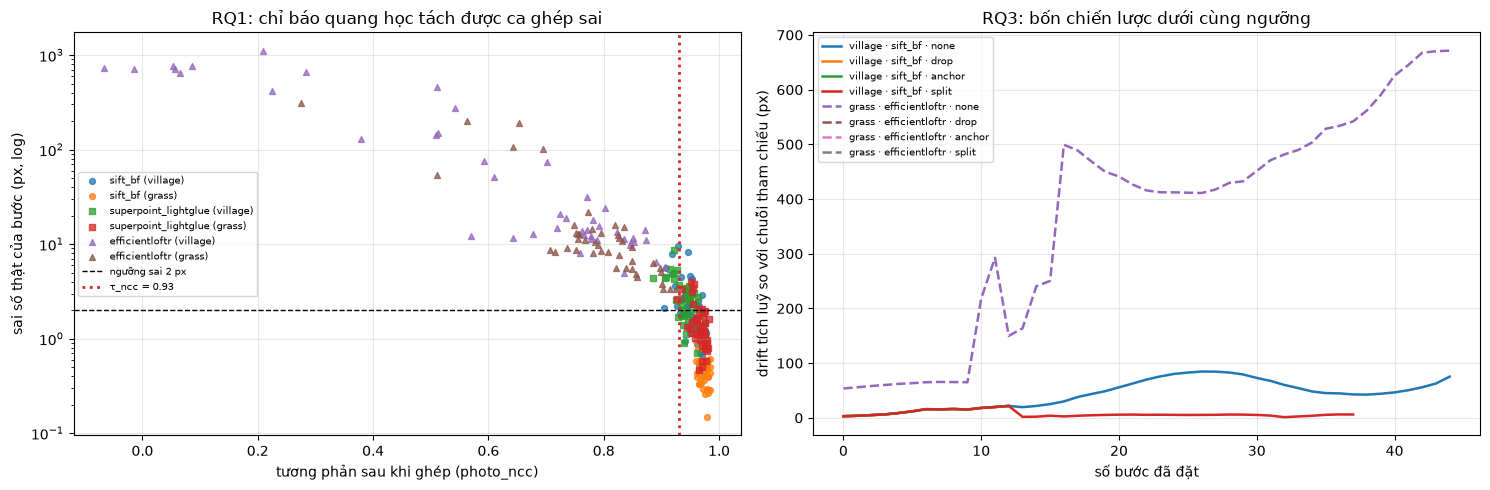

In [13]:
# Biểu đồ: (trái) chỉ báo vs sai số thật; (phải) drift của 4 chiến lược phục hồi.
figure, axes = plt.subplots(1, 2, figsize=(15, 5))
for tier, marker in ((CHEAP, "o"), (STRONG, "s"), (DIAGNOSTIC, "^")):
    for scan in SCANS:
        rows = [r for r in scan["rows"][tier].values() if r["status"] == "success"]
        axes[0].scatter([r["photo_ncc"] for r in rows], [max(r["step_error_px"], 0.05) for r in rows],
                        s=18, marker=marker, alpha=0.75,
                        label=f"{tier} ({scan['sequence'].split('-')[1]})")
axes[0].axhline(TOLERANCE_PX, ls="--", color="k", lw=1, label=f"ngưỡng sai {TOLERANCE_PX:.0f} px")
axes[0].axvline(TAU_STAR, ls=":", color="tab:red", lw=2, label=f"τ_ncc = {TAU_STAR}")
axes[0].set_yscale("log")
axes[0].set_xlabel("tương phản sau khi ghép (photo_ncc)")
axes[0].set_ylabel("sai số thật của bước (px, log)")
axes[0].set_title("RQ1: chỉ báo quang học tách được ca ghép sai")
axes[0].legend(fontsize=7)
axes[0].grid(alpha=.3)
for sequence, style in zip(SEQUENCES, ("-", "--")):
    for row in [r for r in REPORT["rq3"] if r["sequence"] == sequence]:
        axes[1].plot(range(len(row["drift_series"])), row["drift_series"], style, lw=1.8,
                     label=f"{sequence.split('-')[1]} · {row['matcher']} · {row['policy']}")
axes[1].set_xlabel("số bước đã đặt")
axes[1].set_ylabel("drift tích luỹ so với chuỗi tham chiếu (px)")
axes[1].set_title("RQ3: bốn chiến lược dưới cùng ngưỡng")
axes[1].legend(fontsize=7)
axes[1].grid(alpha=.3)
plt.tight_layout()
figure.savefig(TARGET / "summary.png", dpi=110)
plt.show()


## Cách đọc ba bảng dưới

**Bảng RQ1** — mỗi dòng là một chỉ báo của một matcher trên một sequence.

- `ρ` (Spearman) = mức ăn khớp giữa chỉ báo và sai số thật của bước. Gần ±1 là ăn khớp mạnh.
  Dấu **ngược** nhau tuỳ chỉ báo: `photo_ncc`, `overlap_ratio`, `inlier_ratio`, `inliers` cao là *tốt*;
  `rmse_px`, `photo_bad_frac` cao là *xấu*.
- `AUC` = khả năng phân biệt bước sai với bước tốt (0,5 = đoán mò, 1,0 = hoàn hảo).
  Bảng lấy **chiều tách tốt hơn**, nên luôn ≥ 0,5; chiều thật của chỉ báo đọc ở dấu cột `ρ`.
  Với 45 bước thì con số này hơi lạc quan — dùng để **xếp hạng** chỉ báo, đừng trích như số tuyệt đối.
- `bước sai` = số bước có sai số > 2 px (ngưỡng "sai" lấy ở mức nền nhiễu của chính SIFT).

**Bảng RQ2** — mỗi dòng là một chính sách phân luồng.

- `leo thang` = tỉ lệ bước phải gọi matcher mạnh; `giây` = tổng thời gian ghép của chính sách đó;
  `err TB/p95` và `drift cuối` = chất lượng bản đồ cuối cùng (càng nhỏ càng tốt).
- Chính sách tốt là chính sách nằm **gần góc trên-trái**: rẻ như matcher nhẹ mà lỗi như matcher mạnh.

**Bảng RQ3** — cùng một matcher, cùng một ngưỡng, chỉ khác chiến lược khi gặp bước rủi ro.

- `frame` = số frame được đặt vào bản đồ / tổng số frame (bỏ frame thì giảm); `sub` = số mảnh bản đồ
  (tách nhiều mảnh thì tăng); `err max` = bước sai nhất còn nằm trong bản đồ; `drift max` = độ trôi
  lớn nhất so với chuỗi tham chiếu. Chiến lược tốt là chiến lược **giữ được nhiều frame mà drift vẫn thấp**.


In [14]:
rq1 = sorted(REPORT["rq1"], key=lambda r: (r["sequence"], r["tier"],
                                           -abs(r["spearman_vs_step_error"] or 0.0)))
print(f"{'sequence':22} {'matcher':22} {'chỉ báo':16} {'ρ':>7} {'AUC':>6} {'bước sai':>9}")
for row in rq1:
    score = "   n/a" if row["auc_bad_step"] is None else f"{row['auc_bad_step']:6.3f}"
    print(f"{row['sequence']:22} {row['tier']:22} {row['indicator']:16} "
          f"{fmt(row['spearman_vs_step_error'], 7)} {score} {row['n_bad_steps']:9}")
print("(AUC 'n/a' = cửa sổ không có đủ cả bước tốt lẫn bước sai để chấm điểm)")

print()
header = f"{'sequence':22} {'chính sách':16} {'leo thang':>9} {'giây':>8} {'err TB':>8} {'err p95':>8} {'drift cuối':>11}"
print(header)
for row in REPORT["rq2"]:
    label = row["policy"] if row["tau_ncc"] is None else f"{row['policy']}@{row['tau_ncc']}"
    print(f"{row['sequence']:22} {label:16} "
          f"{row['escalation_rate']:9.2f} {row['seconds']:8.1f} {fmt(row['step_error_mean_px'], 8)} "
          f"{fmt(row['step_error_p95_px'], 8)} {fmt(row['final_drift_px'], 11, 1)}")

print()
header = f"{'sequence':22} {'matcher':20} {'chiến lược':10} {'frame':>9} {'sub':>4} {'trigger':>8} {'err max':>9} {'drift max':>10}"
print(header)
for row in REPORT["rq3"]:
    print(f"{row['sequence']:22} {row['matcher']:20} {row['policy']:10} "
          f"{row['frames_placed']:4}/{row['frames_requested']:<4} "
          f"{row['submosaics']:4} {row['triggers']:8} {fmt(row['step_error_max_px'], 9)} {fmt(row['drift_max_px'], 10)}")
print("('n/a' = chiến lược không đặt được frame nào, không có gì để đo)")

dump(TARGET / "report.json", REPORT)
display(Markdown(f"**Đã lưu:** `{TARGET.relative_to(ROOT)}` — `report.json`, `scan_*.json`, `summary.png`"))


sequence               matcher                chỉ báo                ρ    AUC  bước sai
phantom3-grass-kfs     efficientloftr         photo_bad_frac      0.87    n/a        45
phantom3-grass-kfs     efficientloftr         inlier_ratio       -0.83    n/a        45
phantom3-grass-kfs     efficientloftr         inliers            -0.81    n/a        45
phantom3-grass-kfs     efficientloftr         photo_ncc          -0.78    n/a        45
phantom3-grass-kfs     efficientloftr         matches            -0.68    n/a        45
phantom3-grass-kfs     efficientloftr         hull_area_ratio    -0.59    n/a        45
phantom3-grass-kfs     efficientloftr         rmse_px             0.49    n/a        45
phantom3-grass-kfs     efficientloftr         overlap_ratio      -0.21    n/a        45
phantom3-grass-kfs     sift_bf                hull_area_ratio    -0.52    n/a         0
phantom3-grass-kfs     sift_bf                overlap_ratio      -0.31    n/a         0
phantom3-grass-kfs     sift_bf  

**Đã lưu:** `notebooks\outputs\05_failure_aware` — `report.json`, `scan_*.json`, `summary.png`

## Giới hạn phải nêu khi báo cáo

1. **Sai số ở đây là "đồng thuận với matcher tham chiếu"**, không phải sai số ngoài thực địa.
   Kế thừa giới hạn của `RDR-0007`: mức nền của phương pháp chính là sai số của matcher tham chiếu
   và không tách được khỏi sai số của chuỗi.
2. **Chỉ 2 sequence × 2 cửa sổ 45 bước**, chọn vì có lỗi thật — không đại diện cho toàn bộ dataset
   (14 gói NPU Drone-Map). Kết luận về ngưỡng chỉ nên đọc trong phạm vi này.
3. **Ngưỡng `TAU_*` và ngân sách leo thang 25% là giá trị tạm** do notebook đặt để chạy được.
   Nhóm phải chốt bằng `RDR` trước khi dùng cho báo cáo nghiệm thu.
4. **So sánh độ chính xác giữa hai tầng phải đọc kèm độ phân giải.** SuperPoint trích đặc trưng thô
   hơn SIFT ở 640 px, nên RMSE nội tại của nó (~1,2 px) lớn hơn SIFT (~0,4 px) — đó là giới hạn
   độ chính xác của phép nội suy, không phải "kém thông minh hơn". Vì vậy notebook có thêm biến thể
   leo thang lên **ảnh gốc** (`routed_fullres`) để tách hai nguyên nhân này.
5. **RQ3 chỉ so trên hai kịch bản**: matcher nhẹ sai vừa (`village`, SIFT) và matcher yếu vỡ thật
   (`grass`, EfficientLoFTR). Chưa có kịch bản che khuất/mờ chuyển động do người thiết kế.
